# EN3160 – Assignment 3: Neural Networks

| | |
|---|---|
| **Index No.** | 230352K |
| **Name** | Kumara K.B.R |
| **GitHub** | https://github.com/buddhi-rash |

---

This notebook contains the complete work for Assignment 3: code, results and discussion.

| Section | Topic | Tools used |
|---|---|---|
| **Q1** | Two-layer fully connected network with manual back-propagation (CIFAR-10) | `torch` tensors, sigmoid, cross-entropy |
| **Q2** | LeNet-5 vs. a modern small CNN (MNIST) | `torch.nn`, batch norm, dropout, Adam, confusion matrices |
| **Q3** | Transfer learning with ResNet18 (hymenoptera: ants vs. bees) | `torchvision.models`, fine-tuning, feature extraction |

---
# Question 1 — Fully Connected Network with Manual Back-propagation

## 1.1 Objective
Listing 1 of the task sheet trains a **single-layer** network (a linear map from the flattened CIFAR-10 image to 10 outputs) with a mean-squared-error (MSE) loss, using hand-written forward and backward passes. The following changes are required:

- **(a)** add a **middle (hidden) layer with 100 nodes and a sigmoid activation**,
- **(b)** use the **cross-entropy loss**,
- **(c)** run the network for **10 epochs** and report the **training and test accuracies**.

## 1.2 Baseline: the original single-layer network
The first code cell below is Listing 1 as given (20 epochs, MSE loss). It serves as the **baseline** for comparison.

Epoch 1/20, Loss: 0.9769332077503204
Epoch 2/20, Loss: 0.9498110665678978
Epoch 3/20, Loss: 0.936068968653679
Epoch 4/20, Loss: 0.9275178614258767
Epoch 5/20, Loss: 0.9215836952328682
Epoch 6/20, Loss: 0.9171839657425881
Epoch 7/20, Loss: 0.9137710046768188
Epoch 8/20, Loss: 0.9110442957282067
Epoch 9/20, Loss: 0.9088167726993561
Epoch 10/20, Loss: 0.9069643502831459
Epoch 11/20, Loss: 0.9054052955508232
Epoch 12/20, Loss: 0.9040782381892204
Epoch 13/20, Loss: 0.9029399736523628
Epoch 14/20, Loss: 0.901957014977932
Epoch 15/20, Loss: 0.9011032971739769
Epoch 16/20, Loss: 0.9003584219813346
Epoch 17/20, Loss: 0.8997060278058052
Epoch 18/20, Loss: 0.8991328237056733
Epoch 19/20, Loss: 0.898627524793148
Epoch 20/20, Loss: 0.8981810814738274


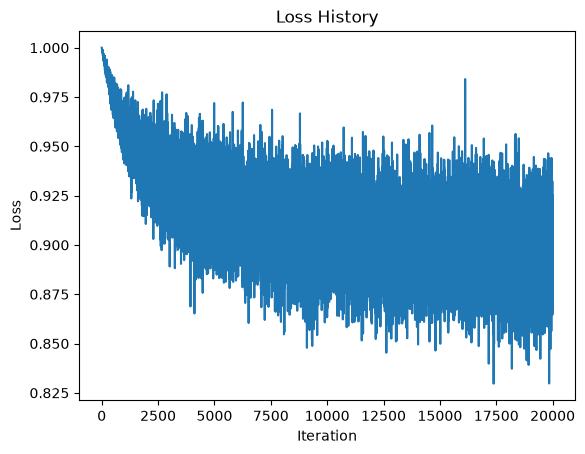

Training accuracy: 32.22%
Test accuracy: 32.42%


In [ ]:
# Imports: PyTorch for tensors, torchvision for CIFAR-10, matplotlib for plotting
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# 1. Dataloading
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)
# Mini-batch size used for training and evaluation
batch_size = 50
# CIFAR-10 training set (50,000 images), normalised to [-1, 1]
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=4)
# CIFAR-10 test set (10,000 images); not shuffled so that evaluation is deterministic
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=4)

# Class names (index -> label)
classes = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10  # Output size (number of classes in CIFAR-10)
# Standard deviation of the small random weight initialisation
std = 1e-5

# Initialize weights and biases
w = (torch.randn(Din, K) * std)  # One layer: directly map input to output
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
# Each iteration of the outer loop is one epoch (a full pass over the training set)
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = (nn.functional.one_hot(labels, K).float())  # Convert labels to one-hot

        # Forward pass
        y_pred = x_train.mm(w) + b  # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # Gradient of the MSE loss with respect to the predictions
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        # Chain rule: dL/dw = x^T . dL/dy_pred (+ regularisation); dL/db sums over the batch
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        # Manual SGD step, applied in place (no autograd is used)
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
# Gradient tracking is disabled because the weights are only evaluated here
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        y_train_pred = x_train.mm(w) + b
        # Predicted class = output unit with the highest score
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

# Accuracy = percentage of correctly classified training images
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

**Baseline result (single layer, MSE loss, 20 epochs)**

| | Accuracy |
|---|---|
| Training | **32.22 %** |
| Test | **32.42 %** |

The loss falls slowly from 0.977 to 0.898 and the accuracy stays low (about 32 %). A single linear layer can only learn linear decision boundaries between the 10 classes, and the training and test accuracies are almost equal, so the model is **under-fitting** (limited capacity) rather than over-fitting.

---
## 1.3 Modified network (parts a and b)

**Architecture:** $\;3072 \rightarrow 100\ (\text{sigmoid}) \rightarrow 10\ (\text{softmax})$

**Forward pass** (for a mini-batch of $N$ images, $X\in\mathbb{R}^{N\times3072}$):

$$Z_1 = XW_1+b_1,\qquad A_1=\sigma(Z_1),\qquad Z_2 = A_1W_2+b_2,\qquad P=\operatorname{softmax}(Z_2)$$

**Cross-entropy loss** (with $Y$ the one-hot labels):

$$L=-\frac1N\sum_{i=1}^{N}\log P_{i,y_i}$$

**Back-propagation** (derived by hand and implemented without autograd; the loss value itself is computed with `nn.CrossEntropyLoss`):

| Quantity | Expression |
|---|---|
| Gradient at the logits | $\dfrac{\partial L}{\partial Z_2}=\dfrac{P-Y}{N}$ |
| Output layer | $\dfrac{\partial L}{\partial W_2}=A_1^\top\dfrac{\partial L}{\partial Z_2},\quad \dfrac{\partial L}{\partial b_2}=\sum_i\dfrac{\partial L}{\partial Z_2}$ |
| Hidden activation | $\dfrac{\partial L}{\partial A_1}=\dfrac{\partial L}{\partial Z_2}W_2^\top$ |
| Through the sigmoid | $\dfrac{\partial L}{\partial Z_1}=\dfrac{\partial L}{\partial A_1}\odot A_1\odot(1-A_1)$ |
| Hidden layer | $\dfrac{\partial L}{\partial W_1}=X^\top\dfrac{\partial L}{\partial Z_1},\quad \dfrac{\partial L}{\partial b_1}=\sum_i\dfrac{\partial L}{\partial Z_1}$ |

**Hyperparameters**

| Parameter | Value | Note |
|---|---|---|
| Hidden nodes | 100 | as required |
| Epochs | 10 | as required (part c) |
| Batch size | 50 | same data pipeline as the baseline |
| Learning rate | $8\times10^{-2}$, decayed by 0.9 every epoch | much larger than the baseline ($2\times10^{-6}$): the cross-entropy gradient is bounded and divided by $N$, and the hidden-layer gradient is further reduced by the sigmoid derivative ($\le 0.25$) and by the small initial $W_2$ |
| Initialisation | $W\sim\mathcal N(0,10^{-5})$, $b=0$ | same as the baseline |
| Regularisation | 0 | none |

Epoch 1/10, Loss: 2.0711891919374468
Epoch 2/10, Loss: 1.819261487364769
Epoch 3/10, Loss: 1.7291698914766311
Epoch 4/10, Loss: 1.6786141978502274
Epoch 5/10, Loss: 1.641053901195526
Epoch 6/10, Loss: 1.6091494407653808
Epoch 7/10, Loss: 1.58250422167778
Epoch 8/10, Loss: 1.5585657439231873
Epoch 9/10, Loss: 1.5366098914146424
Epoch 10/10, Loss: 1.5181932312250137


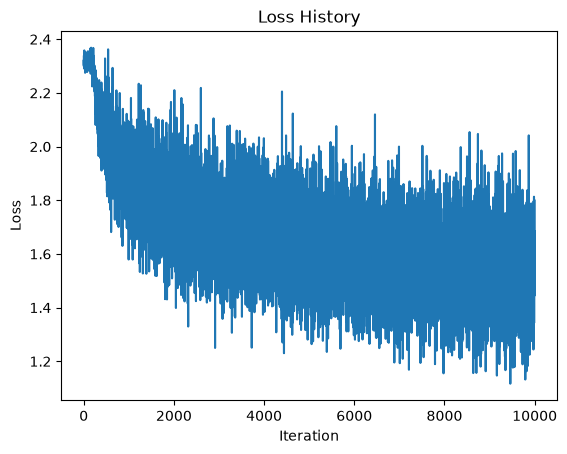

Training accuracy: 48.11%
Test accuracy: 45.82%


In [12]:
# Modified fully connected network with 100 unit hidden layer

# Define the sigmoid activation function
# Sigmoid activation: squashes each hidden pre-activation into (0, 1)
def sigmoid(x):
    return torch.sigmoid(x)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100  # Hidden layer size
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize modified weights and biases
w1 = (torch.randn(Din, H) * std)  # first layer weights ( Din - H)
b1 = torch.zeros(H)
w2 = (torch.randn(H, K) * std)  # second layer weights
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
# Larger step size than the single-layer baseline (hidden-layer gradients are small at the start)
lr = 8e-2  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = (nn.functional.one_hot(labels, K).float())  # Convert labels to one-hot

        # Forward pass
        # Modified using the new hidden layer
        a_1 = x_train.mm(w1) + b1  # First layer activation
        a_1 = sigmoid(a_1)  # Apply sigmoid activation
        y_pred = a_1.mm(w2) + b2  # Output layer activation

        # Loss calculation (Cross-entropy loss) calculated using PyTorch's built-in CrossEntropyLoss function.
        loss = nn.CrossEntropyLoss()(y_pred, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # Modified Backpropagation for the two-layer network
        # Softmax converts the output scores (logits) into class probabilities
        y_pred_probs = torch.softmax(y_pred, dim=1)
        # For softmax + cross-entropy, the gradient w.r.t. the logits is (p - y) / N
        dy_pred =  (y_pred_probs - y_train_onehot) / Ntr

        # Gradients of the output (second) layer
        dw2 = a_1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        # Backpropagate to the hidden layer
        da_1 = dy_pred.mm(w2.t())
        dz_1 = da_1 * (a_1 * (1 - a_1))  # Derivative of sigmoid

        # Compute gradients for the first layer
        dw1 = x_train.t().mm(dz_1) + reg * w1
        db1 = dz_1.sum(dim=0)

        # Parameter update
        # SGD update of both layers' weights and biases
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
# Gradient tracking is disabled because the weights are only evaluated here
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        a_1 = x_train.mm(w1) + b1
        a_1 = sigmoid(a_1)
        y_train_pred = a_1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        a_1 = x_test.mm(w1) + b1
        a_1 = sigmoid(a_1)
        y_test_pred = a_1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

## 1.4 Results and Discussion (part c)

**Accuracy after 10 epochs**

| Model | Loss | Epochs | Training accuracy | Test accuracy |
|---|---|---|---|---|
| Baseline: single layer | MSE | 20 | 32.22 % | 32.42 % |
| **Modified: 100 sigmoid hidden nodes** | **Cross-entropy** | **10** | **48.11 %** | **45.82 %** |

**Observations**
- **The loss decreases steadily.** The epoch-averaged loss falls from 2.07 to 1.52. The loss at the start of training is close to $\ln 10\approx2.30$, the value of a network that guesses uniformly among 10 classes. The per-iteration curve is noisy because each point comes from a single mini-batch of 50 images, but its trend is clearly downward.
- **Accuracy improved by about 13–16 percentage points** (test: 32.42 % → 45.82 %) in half as many epochs. The hidden layer adds a non-linearity and therefore more capacity, and the cross-entropy loss is better suited to classification than MSE on one-hot targets. The two changes were made together, so their individual contributions are not separated here.
- **Mild over-fitting.** The training accuracy is 2.3 points higher than the test accuracy. The loss is still decreasing at epoch 10, so the model has not converged and more epochs would improve it further.
- **Limitation.** A fully connected network flattens the image and discards its spatial structure, so its accuracy on CIFAR-10 saturates well below that of convolutional networks. This motivates the CNNs used in Questions 2 and 3.

---
# Question 2 — LeNet-5 and a Modern Small CNN on MNIST

## 2.1 Objective
- **(a)** Build **LeNet-5** in PyTorch for MNIST and report the training and test accuracy after **10 epochs**.
- **(b)** Build a **modern small CNN** (3 convolutional layers with **batch normalisation** and **dropout**) and train it under the **same conditions**.
- **(c)** For both models, log and plot the **per-epoch training/test loss and accuracy**, and compute the **confusion matrix** on the test set.

## 2.2 Data and training conditions
Both models use identical data and settings so that the comparison is fair.

| Item | Setting |
|---|---|
| Data | MNIST, 60 000 training and 10 000 test images |
| Pre-processing | pad 28×28 → 32×32 (LeNet-5 input size), normalise with MNIST mean 0.1307 and std 0.3081 |
| Optimiser | Adam, learning rate $10^{-3}$, multiplied by 0.9 after each epoch |
| Loss | cross-entropy, plus an L2 penalty $10^{-4}\sum\lVert W\rVert^2$ on weight tensors (not on biases or batch-norm parameters) |
| Batch size / epochs | 50 / 10 |
| Evaluation | after every epoch, on the full training and test sets, with the model in `eval()` mode |

The reported training loss and accuracy are computed in evaluation mode after each epoch (dropout off, batch norm using running statistics), so they are directly comparable with the test values. The L2 penalty is part of the optimised objective but is not included in the logged losses.

## 2.3 Architectures

**LeNet-5** (≈ 61.7 k parameters) uses the scaled tanh $f(x)=1.7159\tanh(\tfrac23x)$ of the original paper and average pooling.

| Layer | Output shape |
|---|---|
| Input | 1 × 32 × 32 |
| Conv 5×5, 6 filters + tanh | 6 × 28 × 28 |
| Avg-pool 2×2 | 6 × 14 × 14 |
| Conv 5×5, 16 filters + tanh | 16 × 10 × 10 |
| Avg-pool 2×2 | 16 × 5 × 5 (400 features) |
| FC 120 + tanh → FC 84 + tanh → FC 10 | 10 |

**Modern small CNN** (`CNN_classifier`, ≈ 105.9 k parameters) uses 3×3 convolutions with padding, batch normalisation, ReLU, max-pooling and dropout ($p=0.3$) before the output layer.

| Layer | Output shape |
|---|---|
| Input | 1 × 32 × 32 |
| Conv 3×3, 8 filters + BN + ReLU + max-pool | 8 × 16 × 16 |
| Conv 3×3, 24 filters + BN + ReLU + max-pool | 24 × 8 × 8 |
| Conv 3×3, 48 filters + BN + ReLU + max-pool | 48 × 4 × 4 (768 features) |
| FC 120 + ReLU + Dropout(0.3) → FC 10 | 10 |

The code below defines both models, the shared training and evaluation functions, the plotting function, and runs the two experiments one after the other.

Training LeNet-5 on MNIST dataset for 10 epochs with lr=0.001, lr_decay=0.9, reg=0.0001
Epoch 1/10 | Train Loss: 0.0866 | Train Accuracy: 97.44% | Test Loss: 0.0862 | Test Accuracy: 97.17%
Epoch 2/10 | Train Loss: 0.0516 | Train Accuracy: 98.42% | Test Loss: 0.0585 | Test Accuracy: 98.03%
Epoch 3/10 | Train Loss: 0.0348 | Train Accuracy: 98.94% | Test Loss: 0.0472 | Test Accuracy: 98.50%
Epoch 4/10 | Train Loss: 0.0331 | Train Accuracy: 98.94% | Test Loss: 0.0424 | Test Accuracy: 98.69%
Epoch 5/10 | Train Loss: 0.0263 | Train Accuracy: 99.15% | Test Loss: 0.0399 | Test Accuracy: 98.62%
Epoch 6/10 | Train Loss: 0.0218 | Train Accuracy: 99.29% | Test Loss: 0.0411 | Test Accuracy: 98.74%
Epoch 7/10 | Train Loss: 0.0165 | Train Accuracy: 99.48% | Test Loss: 0.0368 | Test Accuracy: 98.82%
Epoch 8/10 | Train Loss: 0.0192 | Train Accuracy: 99.39% | Test Loss: 0.0421 | Test Accuracy: 98.66%
Epoch 9/10 | Train Loss: 0.0111 | Train Accuracy: 99.68% | Test Loss: 0.0341 | Test Accuracy: 98.87%
Epo

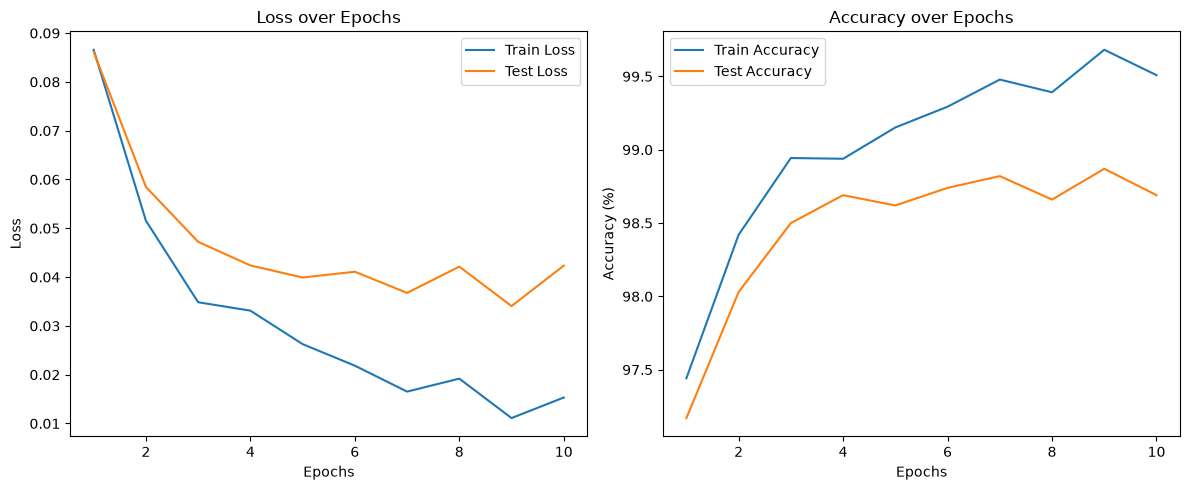

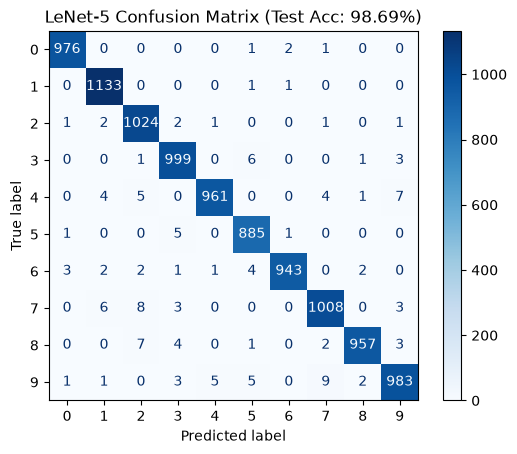

Training CNN_classifier on MNIST dataset for 10 epochs with lr=0.001, lr_decay=0.9, reg=0.0001
Epoch 1/10 | Train Loss: 0.0833 | Train Accuracy: 97.30% | Test Loss: 0.0781 | Test Accuracy: 97.32%
Epoch 2/10 | Train Loss: 0.0359 | Train Accuracy: 98.83% | Test Loss: 0.0381 | Test Accuracy: 98.69%
Epoch 3/10 | Train Loss: 0.0245 | Train Accuracy: 99.20% | Test Loss: 0.0307 | Test Accuracy: 98.93%
Epoch 4/10 | Train Loss: 0.0221 | Train Accuracy: 99.27% | Test Loss: 0.0315 | Test Accuracy: 99.01%
Epoch 5/10 | Train Loss: 0.0192 | Train Accuracy: 99.40% | Test Loss: 0.0300 | Test Accuracy: 98.98%
Epoch 6/10 | Train Loss: 0.0162 | Train Accuracy: 99.47% | Test Loss: 0.0300 | Test Accuracy: 99.00%
Epoch 7/10 | Train Loss: 0.0105 | Train Accuracy: 99.68% | Test Loss: 0.0259 | Test Accuracy: 99.13%
Epoch 8/10 | Train Loss: 0.0086 | Train Accuracy: 99.74% | Test Loss: 0.0253 | Test Accuracy: 99.19%
Epoch 9/10 | Train Loss: 0.0112 | Train Accuracy: 99.63% | Test Loss: 0.0277 | Test Accuracy: 99.

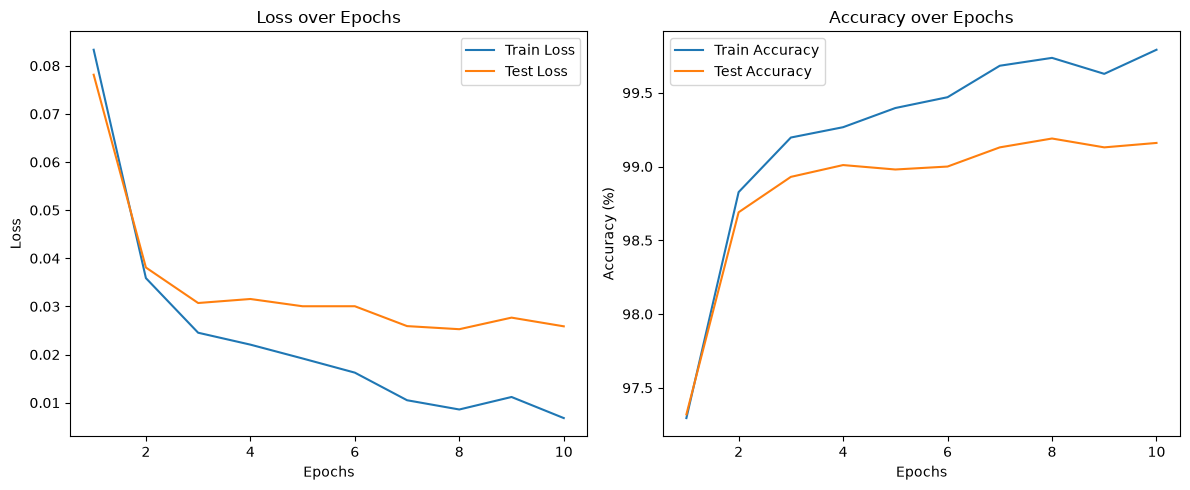

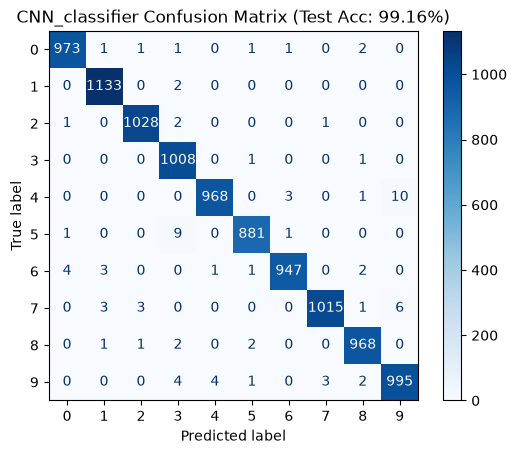

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
# sklearn utilities for computing and plotting the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Creating LeNet 5 using pytorch


# Scaled tanh used in the original LeNet-5 paper: f(x) = 1.7159 * tanh(2x / 3)
def lenet_tanh(x):
    return 1.7159 * torch.tanh((2.0 / 3.0) * x)

# LeNet 5
# LeNet-5: two conv + average-pool stages followed by three fully connected layers (~61.7k parameters)
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)  # Input channels: 1 (grayscale), Output channels: 6 out_size = 28 x 28 x 6
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)  # Average pooling layer out_size = 14 x 14 x 6
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)  # Input channels: 6, Output channels: 16 out_size = 10 x 10 x 16
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)  # Second average pooling layer out_size = 5 x 5 x 16
        self.fc1 = nn.Linear(400, 120)  # Fully connected layer
        self.fc2 = nn.Linear(120, 84)  # Fully connected layer
        self.fc3 = nn.Linear(84, 10)  # Output layer for 10 classes

    # Forward pass: 1x32x32 -> [conv, pool] x 2 -> flatten (400) -> 120 -> 84 -> 10 logits
    def forward(self, x):
        x = lenet_tanh(self.conv1(x))  # Apply tanh activation after first convolution
        x = self.pool1(x)  # Apply average pooling
        x = lenet_tanh(self.conv2(x))  # Apply tanh activation after second convolution
        x = self.pool2(x)  # Apply average pooling
        x = torch.flatten(x, 1)  # Flatten the tensor for fully connected layers
        x = lenet_tanh(self.fc1(x))  # Apply tanh activation after first fully connected layer
        x = lenet_tanh(self.fc2(x))  # Apply tanh activation after second fully connected layer
        x = self.fc3(x)  # Output layer (no activation here as we'll use CrossEntropyLoss)
        return x

# Modern small CNN: 3 x [conv -> batch norm -> ReLU -> max-pool], then a dropout-regularised classifier (~105.9k parameters)
class CNN_classifier(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3,padding=1)  # Input channels: 1 (grayscale), Output channels: 8
        self.norm1 = nn.BatchNorm2d(8)  # Batch normalization layer for 8 channels
        self.conv2 = nn.Conv2d(8, 24, kernel_size=3,padding=1)  # Input channels: 8, Output channels: 24
        self.norm2 = nn.BatchNorm2d(24)  # Batch normalization layer for 24 channels
        self.conv3 = nn.Conv2d(24, 48, kernel_size=3,padding=1)  # Input channels: 24, Output channels: 48
        self.norm3 = nn.BatchNorm2d(48)  # Batch normalization layer for 48 channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)  # max pooling layer
        self.act = nn.ReLU()  # ReLU activation function
        self.dropout = nn.Dropout(p_drop)
        self.fc1 = nn.Linear(4*4*48, 120)  # Fully connected layer
        self.fc2 = nn.Linear(120, 10)  # Output layer for 10 classes

    # Forward pass: 1x32x32 -> 3 conv blocks (spatial size 32 -> 16 -> 8 -> 4) -> flatten (768) -> 120 -> dropout -> 10 logits
    def forward(self, x):
        x = self.pool(self.act(self.norm1(self.conv1(x))))  # Apply batch normalization and ReLU activation after first convolution
        x = self.pool(self.act(self.norm2(self.conv2(x))))  # Apply batch normalization and ReLU activation after second convolution
        x = self.pool(self.act(self.norm3(self.conv3(x))))  # Apply batch normalization and ReLU activation after third convolution
        x = torch.flatten(x, 1)  # Flatten the tensor for fully connected layers
        x = self.act(self.fc1(x))  # Apply ReLU activation after first fully connected layer
        x = self.dropout(x)
        x = self.fc2(x)  # Output layer (no activation here as we'll use CrossEntropyLoss)
        return x

# Training the models
# Training routine shared by both models; logs per-epoch loss and accuracy on the training and test sets
def train(model, epochs, lr, lr_decay, reg):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)  # Move the model to the appropriate device (GPU or CPU)

    # Adam optimiser (the learning rate is decayed manually after every epoch)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_criterian = nn.CrossEntropyLoss()
    
    # Lists that store the per-epoch metrics for plotting
    train_losses = []
    test_losses = []
    train_accuracies = []
    test_accuracies = []

    for epoch in range(epochs):
        model.train()  # Set the model to training mode

        for i, data in enumerate(trainloader_MNIST, 0):
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            
            # L2 penalty on weight tensors only (dim > 1); biases and batch-norm parameters are excluded
            l2 = sum((p ** 2).sum() for p in model.parameters() if p.dim() > 1)
            loss = loss_criterian(outputs, labels) + reg * l2

            # Backpropagation
            # Standard update: clear old gradients, back-propagate, take an optimiser step
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Learning rate decay
        for param_group in optimizer.param_groups:
            param_group['lr'] *= lr_decay

        # End-of-epoch evaluation on the full training and test sets (eval mode: dropout off, batch norm uses running statistics)
        epoch_train_loss, epoch_train_accuracy = evaluate_model(model, trainloader_MNIST, loss_criterian, device)
        epoch_test_loss, epoch_test_accuracy = evaluate_model(model, testloader_MNIST, loss_criterian, device)

        train_losses.append(epoch_train_loss)
        test_losses.append(epoch_test_loss)
        train_accuracies.append(epoch_train_accuracy)
        test_accuracies.append(epoch_test_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
            f"Test Loss: {epoch_test_loss:.4f} | "
            f"Test Accuracy: {epoch_test_accuracy:.2f}%")

    return model, train_losses, test_losses, train_accuracies, test_accuracies

# Computes the average loss and accuracy on a data loader; optionally returns predictions and labels (for the confusion matrix)
def evaluate_model(model, dataloader,  loss_criterian, device, return_preds_labels=False):

    # validation Step after each epoch
    model.eval()  # Set the model to evaluation mode
    correct = 0
    loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in dataloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss += loss_criterian(outputs, labels).item() * inputs.size(0)

            predicted = torch.argmax(outputs, dim=1)
            correct += (predicted == labels).sum().item()
            if return_preds_labels:
                all_preds.append(predicted.cpu())
                all_labels.append(labels.cpu())

        loss = loss / len(dataloader.dataset)
        accuracy = 100 * correct / len(dataloader.dataset)

    if return_preds_labels:
        return loss, accuracy, torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()
    return loss, accuracy

# Plots the training/test loss and accuracy curves side by side
def plot_graphs(tr_loss,tr_acc, te_loss, te_acc):

    epochs = range(1, len(tr_loss) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, tr_loss, label='Train Loss')
    plt.plot(epochs, te_loss, label='Test Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, tr_acc, label='Train Accuracy')
    plt.plot(epochs, te_acc, label='Test Accuracy')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Main experiment: both models are trained with identical settings
if __name__ == "__main__":

    
    # Hyperparameters shared by both models
    epochs = 10
    lr = 0.001
    lr_decay = 0.9
    reg = 0.0001
    batch_size = 50

    criterion = nn.CrossEntropyLoss()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    transform_MNIST = transforms.Compose([
        transforms.Pad(2),  # 28x28 -> 32x32
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)) # Mnist dataset mean and std for normalization
        ])

    trainset_MNIST = torchvision.datasets.MNIST(root="./data_MNIST", train=True, download=True, transform=transform_MNIST)
    trainloader_MNIST = torch.utils.data.DataLoader(trainset_MNIST, batch_size=batch_size, shuffle=True, num_workers=4)
    testset_MNIST = torchvision.datasets.MNIST(root="./data_MNIST", train=False, download=True, transform=transform_MNIST)
    testloader_MNIST = torch.utils.data.DataLoader(testset_MNIST, batch_size=batch_size, shuffle=False, num_workers=4)

    # Train and plot graphs for LeNet-5
    # ---- Model 1: LeNet-5 ----
    model = LeNet5()

    print(f"Training LeNet-5 on MNIST dataset for {epochs} epochs with lr={lr}, lr_decay={lr_decay}, reg={reg}")
    trained_model, train_losses, test_losses, train_accuracies, test_accuracies = train(model, epochs, lr, lr_decay, reg)
    print(f"Final: Train Acc = {train_accuracies[-1]:.2f}% | Test Acc = {test_accuracies[-1]:.2f}%")
    plot_graphs(train_losses, train_accuracies, test_losses, test_accuracies)


    # Confusion matrix on the test set (rows: true digit, columns: predicted digit)
    loss, acc, preds, labels = evaluate_model(trained_model, testloader_MNIST, criterion, device, return_preds_labels=True)
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Blues", values_format="d")
    plt.title(f"LeNet-5 Confusion Matrix (Test Acc: {acc:.2f}%)")
    plt.show()

    # Train and plot graphs for custom designed CNN_classifier
    # ---- Model 2: modern CNN ----
    model = CNN_classifier()

    print(f"Training CNN_classifier on MNIST dataset for {epochs} epochs with lr={lr}, lr_decay={lr_decay}, reg={reg}")
    trained_model, train_losses, test_losses, train_accuracies, test_accuracies = train(model, epochs, lr, lr_decay, reg)
    print(f"Final: Train Acc = {train_accuracies[-1]:.2f}% | Test Acc = {test_accuracies[-1]:.2f}%")
    plot_graphs(train_losses, train_accuracies, test_losses, test_accuracies)


    loss, acc, preds, labels = evaluate_model(trained_model, testloader_MNIST, criterion, device, return_preds_labels=True)
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Blues", values_format="d")
    plt.title(f"CNN_classifier Confusion Matrix (Test Acc: {acc:.2f}%)")
    plt.show()

## 2.4 Results (parts a, b and c)

The cell above prints the per-epoch log, plots the loss and accuracy curves, and shows the test-set confusion matrix for each model (LeNet-5 first, then the modern CNN).

**Final results after 10 epochs**

| Model | Parameters | Train acc. | Test acc. | Train loss | Test loss | Test errors (of 10 000) |
|---|---|---|---|---|---|---|
| LeNet-5 | ≈ 61.7 k | 99.51 % | **98.69 %** | 0.0153 | 0.0423 | 131 |
| Modern CNN (BN + dropout) | ≈ 105.9 k | 99.79 % | **99.16 %** | 0.0068 | 0.0259 | 84 |

**Best epoch (for reference):** LeNet-5 reached 98.87 % test accuracy at epoch 9 and the modern CNN 99.19 % at epoch 8. These values are not used as the main result because there is no separate validation set, so choosing the best epoch on the test set would be optimistic. The final-epoch values above are reported instead.

## 2.5 Discussion

**Learning curves**
- Both models learn quickly: after the first epoch the test accuracy is already above 97 % (LeNet-5 97.17 %, CNN 97.32 %).
- The **modern CNN converges faster and further**. Its test loss reaches about 0.03 by epoch 3 and settles near 0.026, while LeNet-5 reaches about 0.04 and then flattens.
- **LeNet-5 shows mild over-fitting.** Its training loss keeps falling (0.087 → 0.015) while its test loss stops improving after epoch 5 and fluctuates between 0.034 and 0.042. The gap between training and test accuracy is 0.82 points, against 0.63 points for the CNN, so the batch normalisation and dropout of the CNN generalise slightly better.
- The small epoch-to-epoch fluctuations are the usual noise of mini-batch Adam training (the learning rate is still about $4\times10^{-4}$ at the end).

**Confusion matrices**
- Both matrices are strongly diagonal, with every class above 97 % recall. The errors are concentrated in digit pairs that look alike.
- **LeNet-5** (131 errors): the most frequent confusions are 9→7 (9 images), 7→2 (8), 4→9 (7), 8→2 (7), 7→1 (6) and 3→5 (6).
- **Modern CNN** (84 errors, about 36 % fewer): the most frequent confusions are 4→9 (10), 5→3 (9), 7→9 (6) and 9→3 / 9→4 (4 each). It greatly reduces the 7→1, 7→2 and 8→2 errors, but the 4→9 and 5→3 pairs remain, because these digits have very similar shapes when handwritten sloppily.

**Why the modern CNN performs better**
1. **Batch normalisation** stabilises the activations and allows fast, steady training.
2. **ReLU and max-pooling** keep strong local features and avoid the saturation of tanh.
3. **Padded 3×3 convolutions** preserve information at the image borders and build larger receptive fields from small filters.
4. **Dropout** (and the L2 penalty) reduces over-fitting in the larger fully connected layer.

**Caveats.** The difference of about 0.5 percentage points (47 fewer errors) comes from a **single training run** of each model with one random seed. It is consistent over most epochs, but it was not tested over several seeds. Part of the improvement may also come from the CNN's larger size (about 1.7× the parameters).

**Conclusion.** Under identical conditions the modern CNN reaches **99.16 %** test accuracy compared with **98.69 %** for LeNet-5, with a smaller train–test gap and a lower test loss. LeNet-5 is already strong on MNIST, which is a relatively easy dataset.

---
# Question 3 — Transfer Learning with ResNet18 (Hymenoptera Dataset)

## 3.1 Objective
Following the PyTorch transfer-learning tutorial, take **ResNet18 pre-trained on ImageNet-1K** and classify the **hymenoptera** dataset (two classes: *ants* and *bees*) in two ways:
- **(a) Fine-tuning:** start from the pre-trained weights and train **all** layers.
- **(b) Feature extraction:** **freeze** the pre-trained network and train only a new final layer.

Both methods replace the 1000-class output layer by a new `Linear(512, 2)` layer and use identical training settings.

## 3.2 Setup and data
The dataset is small (about 244 training and 153 validation images, which matches the reported accuracies), so **data augmentation** and a pre-trained network are important. The validation set is used as the test set for this question.

| Item | Setting |
|---|---|
| Training transforms | random resized crop 224×224, random horizontal flip, ImageNet normalisation |
| Validation transforms | resize 256, centre crop 224, ImageNet normalisation |
| Optimiser | SGD, learning rate 0.001, momentum 0.9 |
| Scheduler | `StepLR`: learning rate × 0.1 every 7 epochs |
| Loss / epochs / batch size | cross-entropy / 25 / 4 |
| Model selection | the weights with the best validation accuracy are restored at the end of training |
| Hardware | CUDA GPU |

### Libraries

In [3]:
# License: BSD
# Author: Sasank Chilamkurthy

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

# Let cuDNN auto-tune convolution algorithms (faster for fixed input sizes)
cudnn.benchmark = True
# Interactive plotting mode (used by the tutorial's imshow / pause)
plt.ion()   # interactive mode

### Data loading and augmentation

In [4]:
# Data augmentation and normalization for training
# Just normalization for validation
# Training: random crop + flip (augmentation). Validation: deterministic resize + centre crop. Both use the ImageNet mean/std that the pre-trained weights expect.
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Hymenoptera dataset: one sub-folder per class (ants, bees) under train/ and val/
data_dir = 'hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
# Data loaders with a batch size of 4
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

# We want to be able to train our model on an `accelerator <https://pytorch.org/docs/stable/torch.html#accelerators>`__
# such as CUDA, MPS, MTIA, or XPU. If the current accelerator is available, we will use it. Otherwise, we use the CPU.

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


### Sample training batch
A batch of augmented training images with their class labels (the normalisation is undone for display).

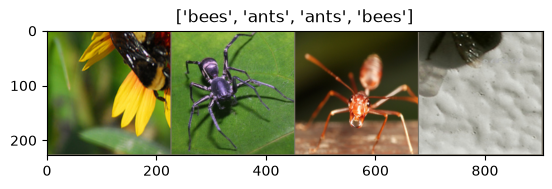

In [5]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    # Undo the ImageNet normalisation so that the image can be displayed
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

### Training and visualisation functions
`train_model` alternates a training and a validation phase in every epoch, logs the loss and accuracy of both phases, and returns the model with the best validation accuracy. `visualize_model` shows predictions on some validation images.

In [7]:
# Training loop: alternates a training and a validation phase each epoch and keeps the weights with the best validation accuracy
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    # The best weights are checkpointed in a temporary folder
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                if phase == 'train':
                    # Update the learning rate once per epoch (StepLR)
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.double() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model

# Shows a few validation images together with the model's predictions
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

---
## 3.3 Part (a) — Fine-tuning
The model is loaded with the ImageNet-1K weights, the final layer is replaced, and **all parameters (≈ 11.18 M) are optimised**.

In [8]:
# Part (a), fine-tuning: load ResNet18 with ImageNet-1K weights and train all layers
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to ``nn.Linear(num_ftrs, len(class_names))``.
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\CHAMA COMPUTERS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:34<00:00, 1.37MB/s]


In [9]:
# Train for 25 epochs; the weights with the best validation accuracy are restored at the end
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 0.7197 Acc: 0.6639
val Loss: 0.6045 Acc: 0.8366

Epoch 1/24
----------
train Loss: 0.4851 Acc: 0.8156
val Loss: 0.3333 Acc: 0.8889

Epoch 2/24
----------
train Loss: 0.4099 Acc: 0.8361
val Loss: 0.3332 Acc: 0.8758

Epoch 3/24
----------
train Loss: 0.5382 Acc: 0.7541
val Loss: 0.4448 Acc: 0.8366

Epoch 4/24
----------
train Loss: 0.5388 Acc: 0.8115
val Loss: 0.3489 Acc: 0.8889

Epoch 5/24
----------
train Loss: 0.5203 Acc: 0.7787
val Loss: 0.5338 Acc: 0.7908

Epoch 6/24
----------
train Loss: 0.4701 Acc: 0.8689
val Loss: 0.2545 Acc: 0.9085

Epoch 7/24
----------
train Loss: 0.3849 Acc: 0.8361
val Loss: 0.2092 Acc: 0.9346

Epoch 8/24
----------
train Loss: 0.3537 Acc: 0.8770
val Loss: 0.2274 Acc: 0.9085

Epoch 9/24
----------
train Loss: 0.3490 Acc: 0.8607
val Loss: 0.1831 Acc: 0.9346

Epoch 10/24
----------
train Loss: 0.2809 Acc: 0.8689
val Loss: 0.1903 Acc: 0.9346

Epoch 11/24
----------
train Loss: 0.2590 Acc: 0.9098
val Loss: 0.1860 Acc: 0.9477

Ep

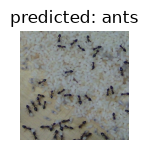

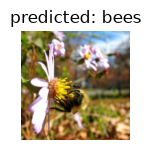

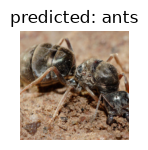

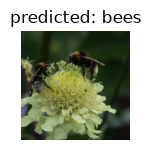

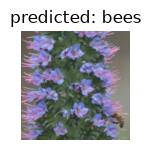

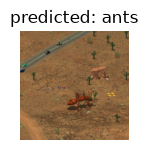

In [10]:
# Predictions of the fine-tuned model on validation images
visualize_model(model_ft)

**Result (a) — fine-tuning, 25 epochs**

| Metric | Value |
|---|---|
| **Best validation accuracy** | **94.77 %** (epoch 11 in the log, which counts from 0) |
| Final epoch: train accuracy / loss | 93.85 % / 0.185 |
| Final epoch: validation accuracy / loss | 94.12 % / 0.164 |
| Validation accuracy after epoch 0 | 83.66 % |
| Training time | 4 min 50 s |

The validation accuracy is unstable in the first epochs (it drops to 79.08 % in epoch 5, when all the pre-trained weights are still being changed with a relatively large learning rate) and stabilises at about 92–95 % from epoch 9 onward, after the learning rate is reduced at epoch 7.

---
## 3.4 Part (b) — ResNet18 as a fixed feature extractor
All pre-trained parameters are **frozen** (`requires_grad = False`) and only the new final layer (**1 026 parameters**) is optimised. The frozen backbone acts as a fixed feature extractor that maps each image to a 512-dimensional vector.

In [11]:
# Part (b), feature extractor: load ResNet18 with ImageNet-1K weights
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
# Freeze all pre-trained layers so that they are not updated during training
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

In [12]:
# Train only the new final layer for 25 epochs; the backbone stays fixed
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.6320 Acc: 0.6721
val Loss: 0.2602 Acc: 0.9020

Epoch 1/24
----------
train Loss: 0.5004 Acc: 0.7541
val Loss: 0.1878 Acc: 0.9412

Epoch 2/24
----------
train Loss: 0.6609 Acc: 0.7213
val Loss: 0.7786 Acc: 0.7451

Epoch 3/24
----------
train Loss: 0.6362 Acc: 0.7336
val Loss: 0.2485 Acc: 0.9150

Epoch 4/24
----------
train Loss: 0.3374 Acc: 0.8525
val Loss: 0.2102 Acc: 0.9281

Epoch 5/24
----------
train Loss: 0.3434 Acc: 0.8607
val Loss: 0.1743 Acc: 0.9477

Epoch 6/24
----------
train Loss: 0.3716 Acc: 0.8361
val Loss: 0.1879 Acc: 0.9477

Epoch 7/24
----------
train Loss: 0.3297 Acc: 0.8770
val Loss: 0.1845 Acc: 0.9412

Epoch 8/24
----------
train Loss: 0.3930 Acc: 0.8402
val Loss: 0.1798 Acc: 0.9477

Epoch 9/24
----------
train Loss: 0.3619 Acc: 0.8320
val Loss: 0.1843 Acc: 0.9346

Epoch 10/24
----------
train Loss: 0.2986 Acc: 0.8566
val Loss: 0.1713 Acc: 0.9477

Epoch 11/24
----------
train Loss: 0.2866 Acc: 0.8811
val Loss: 0.1966 Acc: 0.9412

Ep

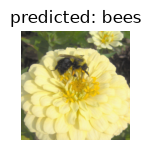

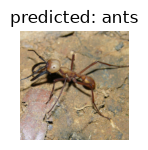

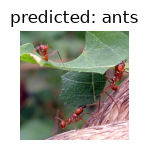

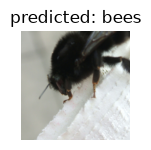

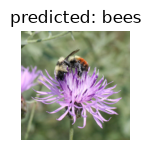

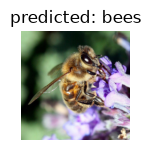

In [13]:
# Predictions of the feature-extractor model on validation images
visualize_model(model_conv)

plt.ioff()
plt.show()

**Result (b) — feature extractor, 25 epochs**

| Metric | Value |
|---|---|
| **Best validation accuracy** | **94.77 %** (epoch 5 in the log, which counts from 0) |
| Final epoch: train accuracy / loss | 86.89 % / 0.312 |
| Final epoch: validation accuracy / loss | 94.12 % / 0.172 |
| Validation accuracy after epoch 0 | 90.20 % |
| Training time | 4 min 29 s |

---
## 3.5 Prediction on a single image
`visualize_model_predictions` loads one image from disk, applies the validation transforms and displays the predicted class. Here it is applied to a validation image from the *bees* folder using the feature-extractor model.

In [14]:
# Predicts the class of a single image file (same preprocessing as the validation set)
def visualize_model_predictions(model,img_path):
    was_training = model.training
    model.eval()

    img = Image.open(img_path)
    img = data_transforms['val'](img)
    img = img.unsqueeze(0)
    img = img.to(device)

    with torch.no_grad():
        outputs = model(img)
        _, preds = torch.max(outputs, 1)

        ax = plt.subplot(2,2,1)
        ax.axis('off')
        ax.set_title(f'Predicted: {class_names[preds[0]]}')
        imshow(img.cpu().data[0])

        model.train(mode=was_training)

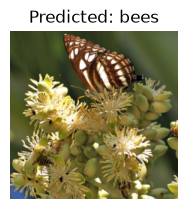

In [16]:
# Classify one validation image from the 'bees' folder with the feature-extractor model
visualize_model_predictions(
    model_conv,
    img_path='hymenoptera_data/val/bees/72100438_73de9f17af.jpg'
)

plt.ioff()
plt.show()

---
## 3.6 Comparison and Discussion

| | (a) Fine-tuning | (b) Feature extractor |
|---|---|---|
| Trainable parameters | ≈ 11.18 M | 1 026 |
| Best validation accuracy | 94.77 % | 94.77 % |
| Final-epoch validation accuracy | 94.12 % | 94.12 % |
| Final-epoch validation loss | 0.164 | 0.172 |
| Final-epoch training accuracy | 93.85 % | 86.89 % |
| Validation accuracy after epoch 0 | 83.66 % | 90.20 % |
| Lowest validation accuracy | 79.08 % (epoch 5) | 74.51 % (epoch 2) |
| Mean validation accuracy, last 10 epochs | 93.79 % | 94.12 % |
| Training time | 4 min 50 s | 4 min 29 s |

**Discussion**
- **Both approaches reach the same accuracy (94.77 % best, 94.12 % final).** The 153 validation images mean that one image is worth 0.65 percentage points, and the two methods are identical at the best and the final epoch (145 and 144 of 153 images correct). The data does not show a winner.
- **Pre-trained features are very effective.** Training only 1 026 parameters is enough to reach about 94 % on this dataset, because the ImageNet features already separate ants from bees (ImageNet-1K itself contains *ant* and *bee* classes). The feature extractor is also **faster to converge**: it reaches 90.2 % after the very first epoch, against 83.7 % for fine-tuning.
- **Fine-tuning fits the training data better** (93.9 % against 86.9 % training accuracy), because every layer can adapt to the new task. With only about 244 training images this extra freedom did not give better validation accuracy, and it makes the early epochs less stable. The feature extractor has a lower risk of over-fitting on such a small dataset.
- **Training accuracy below validation accuracy** in the feature-extractor run is expected: the training accuracy is measured on randomly augmented crops while the weights are changing during the epoch, whereas the validation images are only centre-cropped.
- **The two training times are similar** (about 7 % less for the feature extractor), because the frozen backbone still has to run the forward pass for every image and the data loading with augmentation is also costly. The main saving is in the memory and the number of parameters to optimise, not the time.
- **Validation spikes.** Both runs show occasional dips (79.08 % and 74.51 %) in the early epochs, caused by the small batch size of 4 and the high initial learning rate. The step scheduler removes them in the later epochs.

**Caveats.** The validation set was used both to select the best checkpoint and to report accuracy, so the "best validation accuracy" is slightly optimistic; the final-epoch values are a fairer estimate. Each configuration was run once.

**Conclusion.** Both transfer-learning strategies classify the hymenoptera dataset with about **94–95 %** accuracy. When the target dataset is small and similar to the source data, using the pre-trained network as a **fixed feature extractor** is the cheaper and more stable option, while **fine-tuning** becomes more attractive when more data is available or when the target domain differs from ImageNet.

---
# Summary and Conclusions

| Question | Key outcome |
|---|---|
| **Q1** | Adding a 100-node sigmoid hidden layer and using the cross-entropy loss (manual back-propagation, 10 epochs) raised the accuracy from 32.22 % / 32.42 % (single layer, MSE) to **48.11 % training / 45.82 % test**. A fully connected network is still limited because it ignores spatial structure. |
| **Q2** | After 10 epochs LeNet-5 reached **99.51 % / 98.69 %** (train / test) and the modern CNN with batch norm and dropout reached **99.79 % / 99.16 %**, with fewer test errors (84 against 131) and less over-fitting. Remaining errors are between similar digits such as 4↔9 and 5↔3. |
| **Q3** | ResNet18 pre-trained on ImageNet-1K classified ants vs. bees with **94.77 %** best (94.12 % final) validation accuracy for both **fine-tuning** and **feature extraction**. Feature extraction trains only 1 026 parameters and converges faster, while fine-tuning fits the training data better. |

A common thread across the three questions is the value of **suitable model structure and good priors**: a hidden layer and a proper loss improve a linear classifier, convolutional structure and normalisation improve it further, and transferring pre-trained features gives high accuracy even with very little data.